# Convolution Neural Networks: CIFAR-10 Dataset
### Please let me know if you found any errors, Email me at qiang.sun@utoronto.ca
#### I strongly encourage to buy Google Colab Pro.

This assignment uses the classic [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html) dataset, which is a labeled subset of the 80 million tiny images dataset. It was collected by Alex Krizhevsky, Vinod Nair, and Geoffrey Hinton.

In [ ]:
###checking if we are getting GPU in colab
###if not, Runtime → Change runtime type and Set Hardware accelerator to GPU
!nvidia-smi

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as T

import matplotlib.pyplot as plt
import numpy as np


Using device: mps


# We are gonna to define all the functions so that we can train the model better later


### Data Loader and evaluation [Fill in where you have raise NotImplementedError("Fill me in")]
---




In [3]:
### data loaders (CIFAR-10) ####
def get_cifar10_loaders(batch_size=128, num_workers=2, val_size=5000, seed=42):
    # CIFAR-10 mean/std (common)
    mean = (0.4914, 0.4822, 0.4465)
    std  = (0.2470, 0.2435, 0.2616)

    # Data augmentation ONLY for training
    train_tfms = T.Compose([

        ### please augment the dataset using Random Crop and Horizontal Flip; please check torchvision.transforms
        T.RandomCrop(size=32, padding=4),
        T.RandomHorizontalFlip(p=0.5),

        T.ToTensor(),
        T.Normalize(mean, std),
    ])

    # No augmentation for val/test
    eval_tfms = T.Compose([
        T.ToTensor(),
        T.Normalize(mean, std),
    ])

    # Load the official CIFAR10 train set twice with different transforms
    full_train_for_train = torchvision.datasets.CIFAR10(
        root="./data", train=True, download=True, transform=train_tfms
    )
    full_train_for_eval = torchvision.datasets.CIFAR10(
        root="./data", train=True, download=True, transform=eval_tfms
    )

    testset = torchvision.datasets.CIFAR10(
        root="./data", train=False, download=True, transform=eval_tfms
    )

    # Split indices deterministically
    n_total = len(full_train_for_train)  # 50,000
    n_val = val_size
    n_train = n_total - n_val

    g = torch.Generator().manual_seed(seed)
    train_subset, val_subset = random_split(full_train_for_train, [n_train, n_val], generator=g)

    # IMPORTANT: val subset should use eval transforms (no augmentation)
    # So we re-create val subset with the same indices but using full_train_for_eval
    val_subset = torch.utils.data.Subset(full_train_for_eval, val_subset.indices)

    trainloader = DataLoader(train_subset, batch_size=batch_size, shuffle=True,
                             num_workers=num_workers, pin_memory=True)
    valloader = DataLoader(val_subset, batch_size=batch_size, shuffle=False,
                           num_workers=num_workers, pin_memory=True)
    testloader = DataLoader(testset, batch_size=batch_size, shuffle=False,
                            num_workers=num_workers, pin_memory=True)

    return trainloader, valloader, testloader


### Model Eval
---

In [4]:
###Early Stopping Helper
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0

    def step(self, val_loss):
        # returns True if we should stop
        improved = val_loss < (self.best_loss - self.min_delta)
        if improved:
            self.best_loss = val_loss
            self.counter = 0
            return False
        else:
            self.counter += 1
            return self.counter >= self.patience


###Eval
@torch.no_grad()
def evaluate(model, loader, device, criterion):
    model.eval()
    total, correct, loss_sum = 0, 0, 0.0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)

        loss_sum += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    return loss_sum / total, correct / total

##Train your model

*   Please fill in the blanks


In [5]:
def train_with_early_stopping_adamw(
    model,
    trainloader,
    valloader,
    device,
    epochs=50,
    lr=3e-4,
    weight_decay=1e-2,
    patience=3,
    save_path="best_cifar10_simplecnn.pt",
):
    criterion = nn.CrossEntropyLoss()

    # raise NotImplementedError("Fill me in for the optimizer!")
    optimizer =  torch.optim.Adam( 
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    #raise NotImplementedError("Fill me in for the optimizer!")
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs
    )
    
    early_stopper = EarlyStopping(patience=patience, min_delta=0.0)

    best_val_acc = 0.0

    for epoch in range(1, epochs + 1):
        model.train()
        total, correct, loss_sum = 0, 0, 0.0

        for x, y in trainloader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * x.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)

        scheduler.step()

        train_loss = loss_sum / total
        train_acc = correct / total

        val_loss, val_acc = evaluate(model, valloader, device, criterion)

        # Save best model by val loss
        if val_loss < early_stopper.best_loss:
            torch.save(model.state_dict(), save_path)

        best_val_acc = max(best_val_acc, val_acc)

        print(
            f"Epoch {epoch:3d}/{epochs} | "
            f"train loss {train_loss:.4f} acc {train_acc*100:.2f}% | "
            f"val loss {val_loss:.4f} acc {val_acc*100:.2f}% | "
            f"best val acc {best_val_acc*100:.2f}%"
        )

        if early_stopper.step(val_loss):
            print(f"Early stopping triggered at epoch {epoch}.")
            break

    # Load best weights
    model.load_state_dict(torch.load(save_path, map_location=device))
    model.eval()
    return model

### Visualize data

In [6]:
###trainloader and testloader
trainloader, valloader, testloader = get_cifar10_loaders(
    batch_size=128,
    num_workers=2,
    val_size=5000,
    seed=42
)


100.0%
/Users/dsiqbal/Documents/Uoft/winter 2026/STAD68/.venv/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


/Users/dsiqbal/Documents/Uoft/winter 2026/STAD68/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


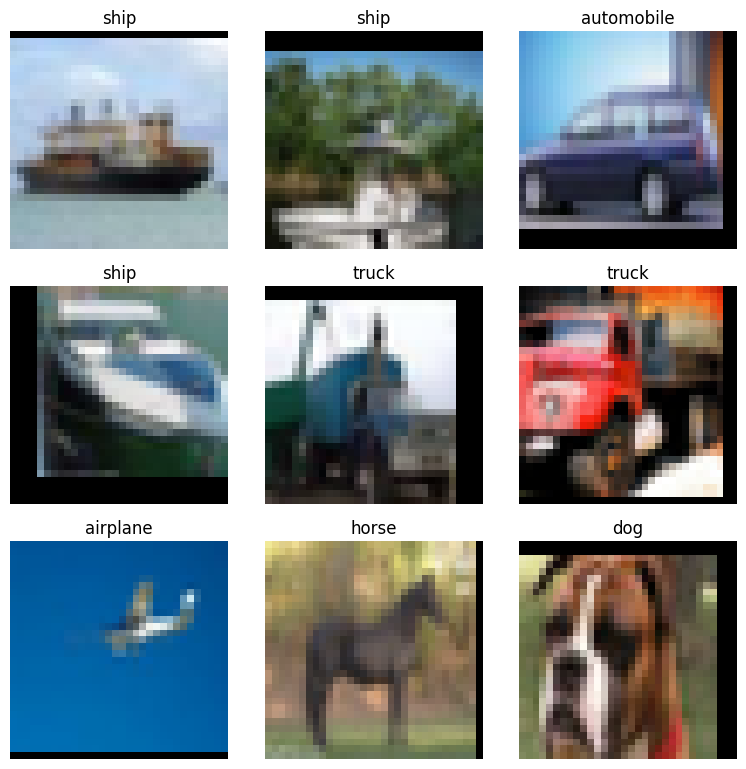

In [7]:
# CIFAR-10 label names (0..9)
classes = ("airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")

# If you used Normalize(mean,std) during training, use the same values here:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

def unnormalize(img):
    m = torch.tensor(mean).view(3, 1, 1)
    s = torch.tensor(std).view(3, 1, 1)
    return img * s + m

def show_batch_from_loader(loader, n=16):
    images, labels = next(iter(loader))   # images: (B,3,32,32), labels: (B,)
    images, labels = images[:n].cpu(), labels[:n].cpu()

    cols = int(np.ceil(np.sqrt(n)))
    rows = int(np.ceil(n / cols))

    plt.figure(figsize=(cols * 2.6, rows * 2.6))
    for i in range(n):
        img = unnormalize(images[i]).clamp(0, 1)          # back to [0,1]
        img = img.permute(1, 2, 0).numpy()                # (H,W,C)

        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(img)
        ax.set_title(classes[int(labels[i])])
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_batch_from_loader(trainloader, n=9)

# Build Model 1
#### Build a CNN model
#### Architecture: from bottom (input) to top (output)

  (input)

	•	Conv(3→32, 3×3) + BN + ReLU     ###check nn.BatchNorm2d
	•	Conv(32→32, 3×3) + BN + ReLU
	•	MaxPool(2) + Dropout(0.25)
	•	Conv(32→64, 3×3) + BN + ReLU
	•	Conv(64→64, 3×3) + BN + ReLU
	•	MaxPool(2) + Dropout(0.25)
	•	Conv(64→128, 3×3) + BN + ReLU
	•	GlobalAvgPool                   ###check nn.AdaptiveAvgPool2d
	•	Linear(128→10)                  ###features to classes

  (softmax + output)
  

#### We will use torch.optim.AdamW with lr=3e-4, weight_decay=1e-2

In [13]:
class SimpleCNN(nn.Module): #TODO: Double check hyperparameters, code is fully AI generated
    def __init__(self, num_classes = 10): 
        super().__init__()
        self.flatten = nn.Flatten()
        self.architecture =nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
        
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1)),
            
            nn.Flatten(), 
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.architecture(x)


# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# To work with cuda and macOS mps
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    elif torch.backends.mps.is_available():
        return torch.device('mps')
    else:
        return torch.device('cpu')

device = get_device()
print('Using device:', device)

model = SimpleCNN(num_classes = 10).to(device)

Using device: mps


### Inspect the model first: Summarize the model first to see we build the right one

In [10]:
#!pip install torchinfo
from torchinfo import summary

In [11]:
summary(model, input_size=(1, 3, 32, 32))  # CIFAR-10: 3x32x32

Layer (type:depth-idx)                   Output Shape              Param #
SimpleCNN                                [1, 10]                   --
├─Sequential: 1-1                        [1, 10]                   --
│    └─Conv2d: 2-1                       [1, 32, 32, 32]           896
│    └─BatchNorm2d: 2-2                  [1, 32, 32, 32]           64
│    └─ReLU: 2-3                         [1, 32, 32, 32]           --
│    └─Conv2d: 2-4                       [1, 32, 32, 32]           9,248
│    └─BatchNorm2d: 2-5                  [1, 32, 32, 32]           64
│    └─ReLU: 2-6                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-7                    [1, 32, 16, 16]           --
│    └─Dropout: 2-8                      [1, 32, 16, 16]           --
│    └─Conv2d: 2-9                       [1, 64, 16, 16]           18,496
│    └─BatchNorm2d: 2-10                 [1, 64, 16, 16]           128
│    └─ReLU: 2-11                        [1, 64, 16, 16]           --
│    └

In [14]:
# Run the model
# Use patience = 3
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu") #! Device already set


model_train = train_with_early_stopping_adamw(
    model,
    trainloader,
    valloader,
    device,
    epochs=50,
    lr=3e-4,   ### 3e-4 usually works well
    weight_decay=1e-2,  ###1e-2 usually works well
    patience=3,
    save_path="best_cifar10_simplecnn_adamw.pt"
)

Epoch   1/50 | train loss 1.6826 acc 39.31% | val loss 1.4407 acc 49.40% | best val acc 49.40%
Epoch   2/50 | train loss 1.3347 acc 53.37% | val loss 1.2892 acc 53.30% | best val acc 53.30%
Epoch   3/50 | train loss 1.2101 acc 58.19% | val loss 1.1706 acc 58.70% | best val acc 58.70%
Epoch   4/50 | train loss 1.1340 acc 60.98% | val loss 1.1165 acc 60.24% | best val acc 60.24%
Epoch   5/50 | train loss 1.0911 acc 62.45% | val loss 1.0581 acc 62.00% | best val acc 62.00%
Epoch   6/50 | train loss 1.0513 acc 64.32% | val loss 1.0092 acc 64.36% | best val acc 64.36%
Epoch   7/50 | train loss 1.0231 acc 65.36% | val loss 0.9410 acc 66.92% | best val acc 66.92%
Epoch   8/50 | train loss 1.0032 acc 66.01% | val loss 1.0068 acc 64.72% | best val acc 66.92%
Epoch   9/50 | train loss 0.9757 acc 67.26% | val loss 0.9654 acc 66.68% | best val acc 66.92%
Epoch  10/50 | train loss 0.9492 acc 68.01% | val loss 0.9328 acc 67.32% | best val acc 67.32%
Epoch  11/50 | train loss 0.9254 acc 69.35% | val 

### Final test evaluation
###What is the test_loss and test accuracy

In [ ]:
raise NotImplementedError("Fill me in for the optimizer!")

print(f"FINAL TEST | loss {test_loss:.4f} acc {test_acc*100:.2f}%")

#Question: What if we do not have the data augmentation?

[Summarize your findings here]

#Build Model 2: VGG-style model and repeat the above analysis for model 1
###Architecture

    Input: (N, 3, 32, 32)

    Block 1 (channels 64)
      1.	Conv3×3, 3→64, pad=1 → (N, 64, 32, 32)
      2.	BN(64) + ReLU
      3.	Conv3×3, 64→64, pad=1 → (N, 64, 32, 32)
      4.	BN(64) + ReLU
      5.	MaxPool2×2 → (N, 64, 16, 16)
      6.	Dropout(p=0.25)

    Block 2 (channels 128)
      7.	Conv3×3, 64→128, pad=1 → (N, 128, 16, 16)
      8.	BN(128) + ReLU
      9.	Conv3×3, 128→128, pad=1 → (N, 128, 16, 16)
      10.	BN(128) + ReLU
      11.	MaxPool2×2 → (N, 128, 8, 8)
      12.	Dropout(p=0.25)

    Block 3 (channels 256)
      13.	Conv3×3, 128→256, pad=1 → (N, 256, 8, 8)
      14.	BN(256) + ReLU
      15.	Conv3×3, 256→256, pad=1 → (N, 256, 8, 8)
      16.	BN(256) + ReLU
      17.	MaxPool2×2 → (N, 256, 4, 4)
      18.	Dropout(p=0.25)

    Head
      19.	AdaptiveAvgPool2d(1) → (N, 256, 1, 1)
      20.	Flatten → (N, 256)
      21.	Linear 256→10 → (N, 10)

    Softmax + Output

In [ ]:
class VGGSmallCIFAR(nn.Module):
    """
    VGG-style network for CIFAR-10:
      (64x2) -> pool -> (128x2) -> pool -> (256x2) -> pool -> GAP -> FC
    Input:  (N,3,32,32)
    Output: (N,10)
    """
    def __init__(self, num_classes=10, dropout=0.25):
        super().__init__()

        raise NotImplementedError("Fill me in for the optimizer!")

    def forward(self, x):

        raise NotImplementedError("Fill me in for the optimizer!")

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model2 = VGGSmallCIFAR(num_classes=10).to(device)

summary(model2, input_size=(1, 3, 32, 32))

# x = torch.randn(4, 3, 32, 32).to(device)
# y = model(x)
# print("Output shape:", y.shape)  # should be torch.Size([4, 10])

In [ ]:
model2_train = train_with_early_stopping_adamw(
    model2,
    trainloader,
    valloader,
    device,
    epochs=50,
    lr=3e-4,              # lr = 3e-4
    weight_decay=1e-2,    # patience =
    patience=3,
    save_path="best_vggsmall_cifar10_adamw.pt"
)

# Final test verification
test_loss, test_acc = evaluate(model_train2, testloader, device, nn.CrossEntropyLoss())
print(f"FINAL TEST | loss {test_loss:.4f} acc {test_acc*100:.2f}%")

#Build Model 3: Resnet
#### For Resnet, please refer to the paper: https://arxiv.org/abs/1512.03385

####Architecture
    Overall structure (CIFAR ResNet)

    Input: (N, 3, 32, 32)

    Stem
      1.	Conv 3×3, 3 → 16, stride 1, pad 1
      2.	BatchNorm(16)
      3.	ReLU
    Output: (N, 16, 32, 32)

    ⸻

    Residual stages (BasicBlock)

    Each BasicBlock is:
      •	Conv 3×3 (stride = s), BN, ReLU
      •	Conv 3×3 (stride = 1), BN
      •	Add shortcut (identity if shape matches, else 1×1 conv + BN)
      •	ReLU

    Stage 1: width 16, spatial 32×32
      •	3 BasicBlocks (for ResNet-20)
      •	First block stride=1 (no downsampling)
    Output stays: (N, 16, 32, 32)

    Stage 2: width 32, spatial 16×16
      •	3 BasicBlocks
      •	First block uses stride=2 → downsamples 32×32 → 16×16
      •	Shortcut uses 1×1 conv stride=2 (because channels/spatial change)
    Output: (N, 32, 16, 16)

    Stage 3: width 64, spatial 8×8
      •	3 BasicBlocks
      •	First block uses stride=2 → downsamples 16×16 → 8×8
      •	Shortcut uses 1×1 conv stride=2
    Output: (N, 64, 8, 8)

    ⸻

    Head
      •	Global Average Pool (AdaptiveAvgPool2d(1)): (N, 64, 1, 1)
      •	Flatten → (N, 64)
      •	Linear 64 → 10 → (N, 10)


####Please repeat your analysis and then summarize your findings

In [ ]:
###THe BasicBlock is complete
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes: int, planes: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(planes)

        # Projection shortcut if shape changes (stride or channels)
        self.shortcut = nn.Identity()
        if stride != 1 or in_planes != planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes),
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)
        out = F.relu(out, inplace=True)
        return out



####Please fill in the blanks in this class
class ResNetCIFAR(nn.Module):
    """
    CIFAR-style ResNet:
      stem: 3x3 conv, 16ch
      stage1: 16ch blocks, stride 1
      stage2: 32ch blocks, stride 2
      stage3: 64ch blocks, stride 2
      GAP + FC
    """
    def __init__(self, block, num_blocks, num_classes=10):
        super().__init__()
        self.in_planes = 16

        raise NotImplementedError("Fill me in for the optimizer!")


    ####helper: _make_layer for layers 1, 2, 3
    def _make_layer(self, block, planes, n_blocks, stride):
        strides = [stride] + [1] * (n_blocks - 1)
        layers = []
        for s in strides:
            layers.append(block(self.in_planes, planes, stride=s))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x):
        raise NotImplementedError("Fill me in for the optimizer!")

        return out


####main restnet
def resnet20_cifar(num_classes=10):
    # 6n+2 layers, n=3 -> 20
    return ResNetCIFAR(BasicBlock, [3, 3, 3], num_classes=num_classes)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model3 = resnet20_cifar(num_classes=10).to(device)

summary(model3, input_size=(1, 3, 32, 32))

In [ ]:
model3_train = train_with_early_stopping_adamw(
    model3,
    trainloader,
    valloader,
    device,
    epochs=50,  ###epochs = 50
    lr=3e-4,
    weight_decay=1e-2,  ###
    patience=3,   ###
    save_path="best_resnet20_cifar10_adamw.pt"
)

In [ ]:
raise NotImplementedError("Fill me in for the optimizer!")

print(f"FINAL TEST | loss {test_loss:.4f} acc {test_acc*100:.2f}%")

#Summarize your findings here

[Fill in here]